In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("car_sales_data.csv")

In [3]:
df.head()

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300,3074
1,Porsche,718 Cayman,4.0,Petrol,2016,57850,49704
2,Ford,Mondeo,1.6,Diesel,2014,39190,24072
3,Toyota,RAV4,1.8,Hybrid,1988,210814,1705
4,VW,Polo,1.0,Petrol,2006,127869,4101


In [4]:
df.tail()

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
49995,BMW,M5,5.0,Petrol,2018,28664,113006
49996,Toyota,Prius,1.8,Hybrid,2003,105120,9430
49997,Ford,Mondeo,1.6,Diesel,2022,4030,49852
49998,Ford,Focus,1.0,Diesel,2016,26468,23630
49999,VW,Golf,1.4,Diesel,2012,109300,10400


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Manufacturer         50000 non-null  str    
 1   Model                50000 non-null  str    
 2   Engine size          50000 non-null  float64
 3   Fuel type            50000 non-null  str    
 4   Year of manufacture  50000 non-null  int64  
 5   Mileage              50000 non-null  int64  
 6   Price                50000 non-null  int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 2.7 MB


In [6]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include="number"
)

# Select categorical/text columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
)

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

Numerical columns:
['Engine size', 'Year of manufacture', 'Mileage', 'Price']

Categorical columns:
['Manufacturer', 'Model', 'Fuel type']


In [7]:
print("Before cleaning :",df.shape) #dataset contains 5000 rows, and 7 columns

Before cleaning : (50000, 7)


In [8]:
print("Duplicate rows:", df.duplicated().sum())
 # 12 duplicated rows are there

Duplicate rows: 12


In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
print("After cleaning :",df.shape) # 6 duplicated rows are get removed permanently

After cleaning : (49988, 7)


In [12]:
df.isnull().sum() #there is no null values

Manufacturer           0
Model                  0
Engine size            0
Fuel type              0
Year of manufacture    0
Mileage                0
Price                  0
dtype: int64

In [13]:
df['Manufacturer'].unique()

<StringArray>
['Ford', 'Porsche', 'Toyota', 'VW', 'BMW']
Length: 5, dtype: str

In [14]:
df['Model'].unique()

<StringArray>
[    'Fiesta', '718 Cayman',     'Mondeo',       'RAV4',       'Polo',
      'Focus',      'Prius',       'Golf',         'Z4',      'Yaris',
        '911',     'Passat',         'M5',    'Cayenne',         'X3']
Length: 15, dtype: str

In [15]:
df['Fuel type'].unique()

<StringArray>
['Petrol', 'Diesel', 'Hybrid']
Length: 3, dtype: str

In [16]:
#finding if suspicious values are present or not
df.describe()

,Engine size,Year of manufacture,Mileage,Price
count,49988.000000,49988.000000,49988.000000,49988.000000
mean,1.773140,2004.209630,112515.561215,13829.112387
std,0.734149,9.646056,71624.341062,16417.812203
min,1.000000,1984.000000,630.000000,76.000000
25%,1.400000,1996.000000,54375.250000,3059.750000
50%,1.600000,2004.000000,101011.500000,7971.000000
75%,2.000000,2012.000000,158617.250000,19028.500000
max,5.000000,2022.000000,453537.000000,168081.000000


In [17]:
(df["Price"] <= 0).sum()

np.int64(0)

In [18]:
(df["Mileage"] <=0).sum()

np.int64(0)

In [19]:
df['Year of manufacture'].max()

np.int64(2022)

In [20]:
df['Year of manufacture'].min()

np.int64(1984)

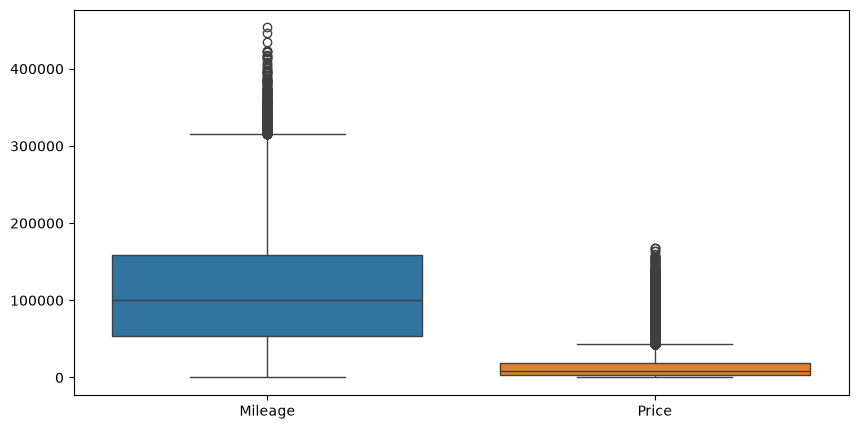

In [21]:
#outliers
plt.figure(figsize=(10,5))
sns.boxplot(data=df[["Mileage","Price"]])
plt.show()

In [22]:
for col in ["Mileage", "Price"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[
        (df[col] < Q1 - 1.5 * IQR) |
        (df[col] > Q3 + 1.5 * IQR)
    ]

    print(col, "outliers:", len(outliers))

Mileage outliers: 385
Price outliers: 2649


**Outlier Treatment**

Potential outliers were identified using the Interquartile Range (IQR) method. The flagged mileage and price observations were investigated rather than automatically removed. Since unusually high mileage and price can occur in genuine. This approach preserves valid information and avoids unnecessary data loss.

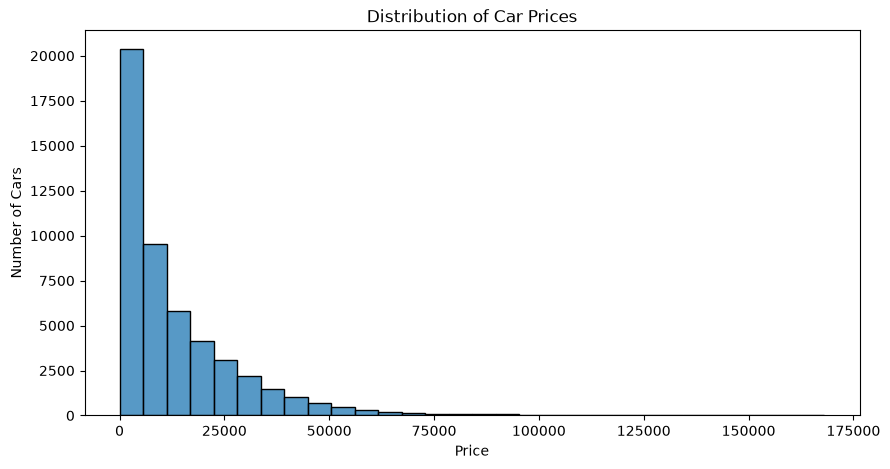

In [23]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Price",bins=30)
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of Cars")

plt.show()

**Chart 1: Distribution of Car Prices**

**Observation:** The histogram shows a positively skewed distribution of car prices. Most observations are concentrated in the lower price intervals, and the frequency of cars decreases as prices increase. A long right tail indicates that a relatively small number of cars have much higher recorded prices than the majority of the dataset.

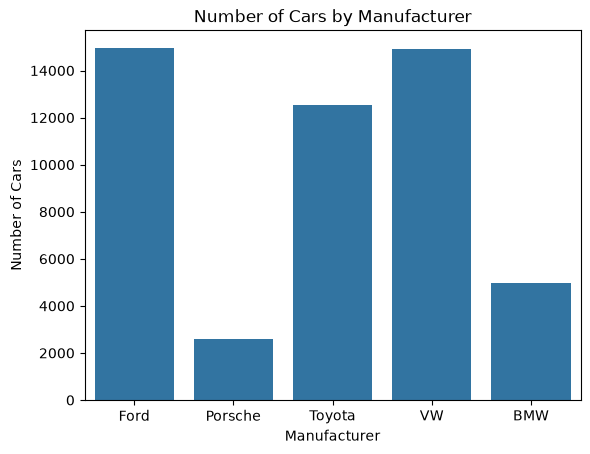

In [24]:
sns.countplot(data=df, x="Manufacturer")
plt.title("Number of Cars by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Cars")
plt.show()

Chart 2: Number of Cars by Manufacturer

Observation: Ford and VW have the highest representation in the dataset, with
approximately 15,000 records each. Toyota is the third most represented manufacturer, while BMW and Porsche have fewer records. These counts describe the distribution of manufacturers in the dataset and do not necessarily represent their overall market popularity.

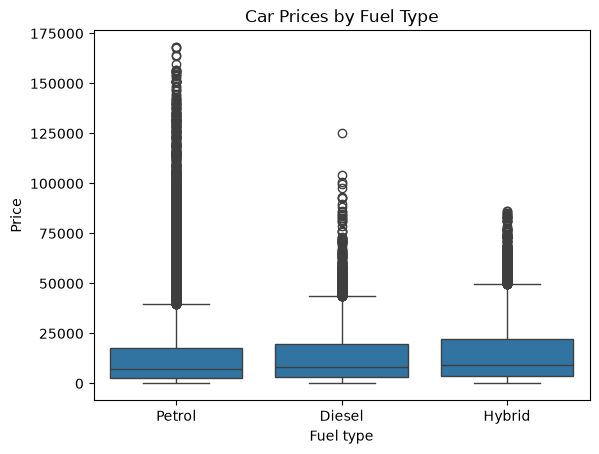

In [25]:
sns.boxplot(data=df, x="Fuel type", y="Price")
plt.title("Car Prices by Fuel Type")
plt.show()

**Chart 3: Car Prices by Fuel Type**

**Observation:** The boxplot suggests that Hybrid cars have a higher median price than Petrol and Diesel cars in this dataset. Hybrid vehicles also show a wider interquartile range, indicating greater variation in the middle 50% of their prices. All three fuel categories contain numerous high-price outliers, with Petrol showing the most extreme values. These findings describe the dataset and do not establish that fuel type causes differences in price.

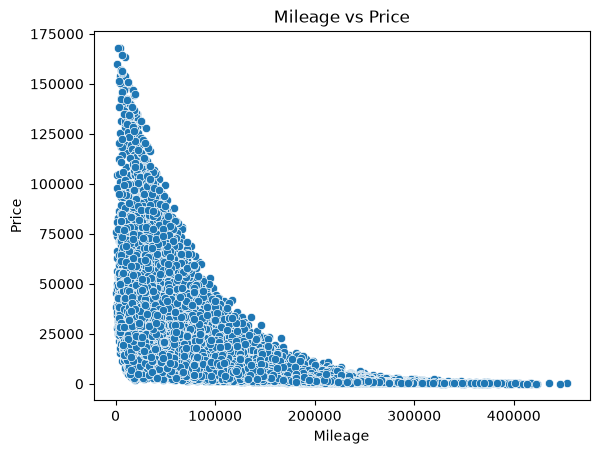

In [26]:
sns.scatterplot(data=df, x="Mileage", y="Price")
plt.title("Mileage vs Price")
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.show()

**Chart 4: Relationship Between Mileage and Price**

**Observation:** The scatter plot shows a strong negative, nonlinear association between mileage and car price in this dataset. Cars with lower mileage exhibit a wider range of prices, while cars with higher mileage are generally concentrated in the lower price range. This suggests that mileage is associated with car price, although other factors, such as manufacturer, model, fuel type, and year of manufacture, may also influence the observed prices.

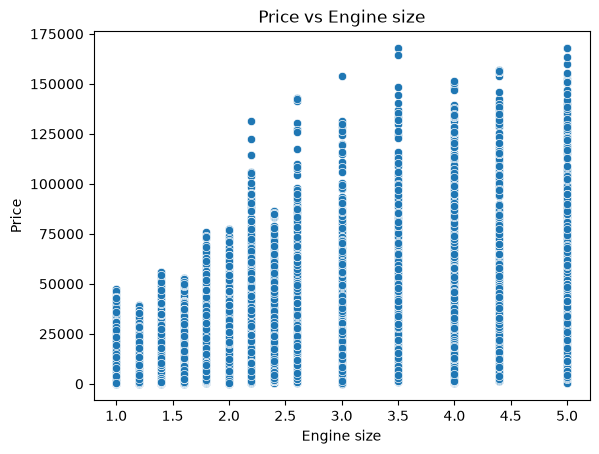

In [27]:
sns.scatterplot(data=df, x="Engine size", y="Price")
plt.title("Price vs Engine size")
plt.show()

**Chart 5: Relationship Between Engine Size and Price**

**Observation:** The scatter plot suggests that cars with larger engine sizes tend to have a wider range of prices and include many of the highest-priced observations. Cars with smaller engines are more concentrated in the lower price ranges. However, substantial price variation exists within engine-size categories, indicating that other factors may also be associated with car prices.

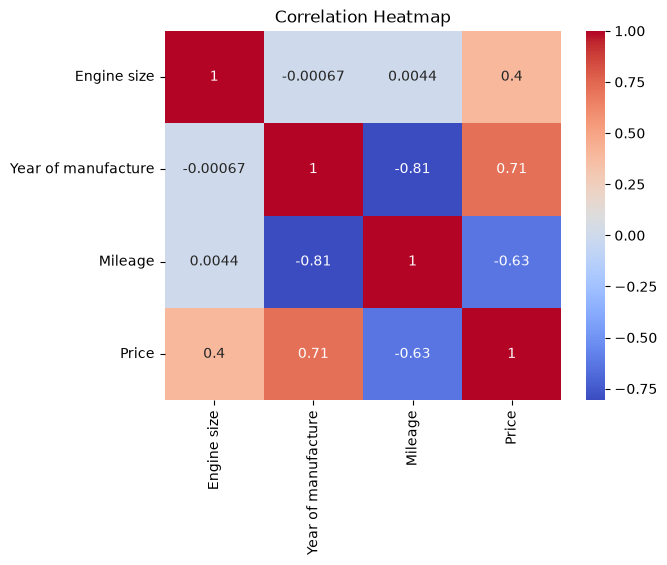

In [28]:
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Chart 6: Correlation Heatmap of Numerical Variables**

**Observation:** The heatmap shows a strong negative correlation between year of manufacture and mileage (−0.81), indicating that newer cars generally have lower mileage in this dataset. Year of manufacture has a positive correlation with price (0.71), while mileage has a negative correlation with price (−0.63). Engine size has a moderate positive correlation with price (0.40). These relationships are associations within the dataset and do not establish causation.